In [19]:
# plotting gradient growth/decay
import numpy as np
import pandas as pd

def scalar_deep_grad(a, L, x=1.0, y=1.0):
    # Forward Pass
    h = (a ** L) * x
    # Loss Derivative
    dL_dh = h - y
    # Output Derivative with respect to Weight
    dH_da = L * (a ** (L - 1)) * x
    # Backward Pass / Chain Rule
    return abs(dL_dh * dH_da)

# L
depths = [1, 2, 5, 10, 20]
# a
a_values = [0.5, 0.9, 1.0, 1.1, 1.5]

rows = []
for a in a_values:
    for L in depths:
        rows.append({"a": a, "depth L": L, "|dL/da|": scalar_deep_grad(a, L)})

df_scalar = pd.DataFrame(rows)
df_scalar_pivot = df_scalar.pivot(index="depth L", columns="a", values="|dL/da|")
df_scalar_pivot

a,0.5,0.9,1.0,1.1,1.5
depth L,,,,,
1,0.500000,0.100000,0.0,0.100000,5.000000e-01
2,0.750000,0.342000,0.0,0.462000,3.750000e+00
5,0.302734,1.343398,0.0,4.469238,1.669043e+02
10,0.019512,2.523353,0.0,37.579614,2.178394e+04
20,0.000038,2.373239,0.0,700.577375,1.473868e+08


/var/folders/yd/fwg_prv93zz2cr4rk5mdflnr0000gn/T/ipykernel_21192/4022014825.py:6: RuntimeWarning: divide by zero encountered in log10
  plt.plot(depths, np.log10(grads), marker="o", label=f"a={a}")


<module 'matplotlib.pyplot' from '/Users/yanrui/Developer/CSCourses/csci3151/.venv/lib/python3.15/site-packages/matplotlib/pyplot.py'>

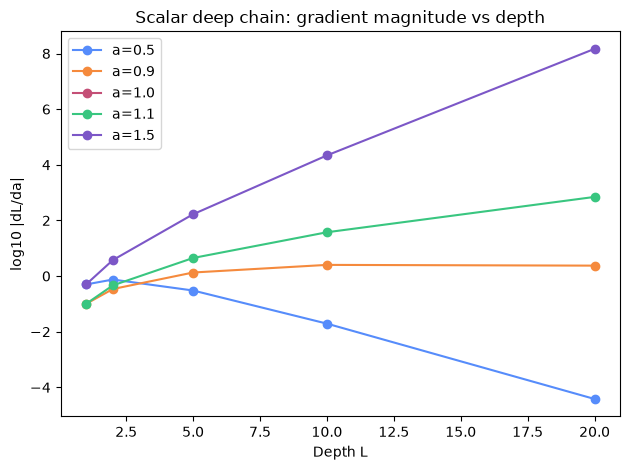

In [20]:
import matplotlib.pyplot as plt

plt.figure()
for a in a_values:
    grads = [scalar_deep_grad(a, L) for L in depths]
    plt.plot(depths, np.log10(grads), marker="o", label=f"a={a}")
plt.xlabel("Depth L")
plt.ylabel("log10 |dL/da|")
plt.title("Scalar deep chain: gradient magnitude vs depth")
plt.legend()
plt.tight_layout()
plt

In [21]:
import torch
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Prepare data
X, y = make_moons(n_samples=1000, noise=0.2, random_state=0)
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.3, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

X_batch = torch.tensor(X_train_scaled[:128], dtype=torch.float32)
y_batch = torch.tensor(y_train[:128], dtype=torch.long)

def make_mlp(depth, hidden_dim=64):
    layers = []
    in_dim = 2
    for _ in range(depth):
        layers.append(torch.nn.Linear(in_dim, hidden_dim))
        layers.append(torch.nn.ReLU())
        in_dim = hidden_dim
    layers.append(torch.nn.Linear(in_dim, 2))
    return torch.nn.Sequential(*layers)

def grad_norms_for_depth(depth):
    torch.manual_seed(0)
    model = make_mlp(depth)
    criterion = torch.nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=0.1)

    # One (or a few) training steps
    for _ in range(5):
        optimizer.zero_grad()
        logits = model(X_batch)
        loss = criterion(logits, y_batch)
        loss.backward()
        optimizer.step()

    # Compute grad norms from another backward pass (to avoid momentum effects)
    optimizer.zero_grad()
    logits = model(X_batch)
    loss = criterion(logits, y_batch)
    loss.backward()

    norms = []
    layer_idx = 0
    for module in model:
        if isinstance(module, torch.nn.Linear):
            if module.weight.grad is not None:
                gnorm = module.weight.grad.norm().item()
            else:
                gnorm = 0.0
            norms.append({"depth": depth, "layer": layer_idx, "grad_norm": gnorm})
            layer_idx += 1
    return norms

rows = []
for depth in [1, 3, 6]:
    rows.extend(grad_norms_for_depth(depth))

df_norms = pd.DataFrame(rows)
df_norms

,depth,layer,grad_norm
0,1,0,0.105765
1,1,1,0.493650
2,3,0,0.030051
3,3,1,0.170014
4,3,2,0.142462
5,3,3,0.147285
6,6,0,0.001609
7,6,1,0.012164
8,6,2,0.011972
9,6,3,0.008038


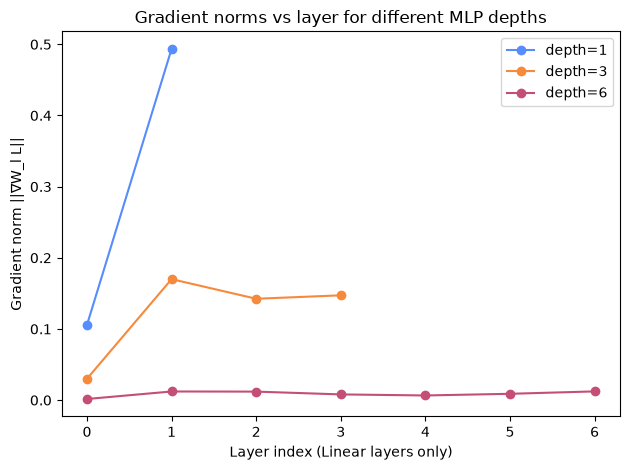

In [22]:
plt.figure()
for depth, subdf in df_norms.groupby("depth"):
    plt.plot(subdf["layer"], subdf["grad_norm"], marker="o", label=f"depth={depth}")
plt.xlabel("Layer index (Linear layers only)")
plt.ylabel("Gradient norm ||∇W_l L||")
plt.title("Gradient norms vs layer for different MLP depths")
plt.legend()
plt.tight_layout()